# Task 3 · Track Fast Motion (30 marks)

Make Lucas-Kanade follow large motion: iterate it, track many points reliably,
and start it from SIFT matches when the motion is too large. The flow $(u, v)$
moves a point from image0 to image1: `[x + u, y + v]`.

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [1]:
# PROVIDED: run this cell first (save task2.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sampling import bilinear_sample
from provided.sift import sift_matches, track_with_sift
from provided.task3.steps import compare_pair, error_sweep

use_my_functions(2)               # your Task 1 and 2 functions, from the saved notebooks

your functions from task1.ipynb, task2.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features, lucas_kanade_update, one_step_flow


## 3.1 Iterative Lucas-Kanade (9 marks)

Start from $(u,v)=(0,0)$ or from a given initial guess, warp the second image
with bilinear sampling, and repeat the Task 2 update until the increment is
small or a maximum iteration count is reached. The provided cell adds your
iterative curve to the error sweep of Task 2.3.

In [2]:
# YOUR CODE: Task 3.1

def track_point(image0, image1, point, window_radius=7, max_iterations=10, tolerance=1e-3,
                grad0=None, initial=None):
    """Track one point from image0 to image1 by repeating the Task 2 update (Task 3.1).

    Returns (new_point, ok): new_point = np.array([x + u, y + v]); ok is False if
    the window leaves either image or the update cannot be solved.
    """
    ix, iy = grad0 if grad0 is not None else spatial_gradients(image0)
    x, y = float(point[0]), float(point[1])
    r = int(window_radius)
    h, w = np.shape(image0)
    u, v = (0.0, 0.0) if initial is None else (float(initial[0]), float(initial[1]))

    # the template window must sit inside image0, 1 pixel away from the border
    if x - r < 1 or y - r < 1 or x + r > w - 2 or y + r > h - 2:
        return np.array([x + u, y + v]), False

    dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
    xs, ys = x + dx, y + dy
    template, _ = bilinear_sample(image0, xs, ys)
    gx, _ = bilinear_sample(ix, xs, ys)
    gy, _ = bilinear_sample(iy, xs, ys)

    for _ in range(int(max_iterations)):
        warped, inside = bilinear_sample(image1, xs + u, ys + v)
        if not inside.all():
            return np.array([x + u, y + v]), False
        step = lucas_kanade_update(gx, gy, warped - template)
        if step is None:
            return np.array([x + u, y + v]), False
        u += step[0]
        v += step[1]
        if not (np.isfinite(u) and np.isfinite(v)):
            return np.array([x, y]), False
        if np.hypot(*step) < tolerance:
            break
    return np.array([x + u, y + v]), True

In [3]:
check("3.1")

Task 3.1 checks
  PASS  track point recovers a subpixel shift
  PASS  iterations do not hurt
  PASS  track point fails when the window leaves the image
  PASS  track point starts from the initial guess
4 of 4 passed


True

  saved outputs/task3/error_sweep.json
  saved outputs/task3/error_sweep.png


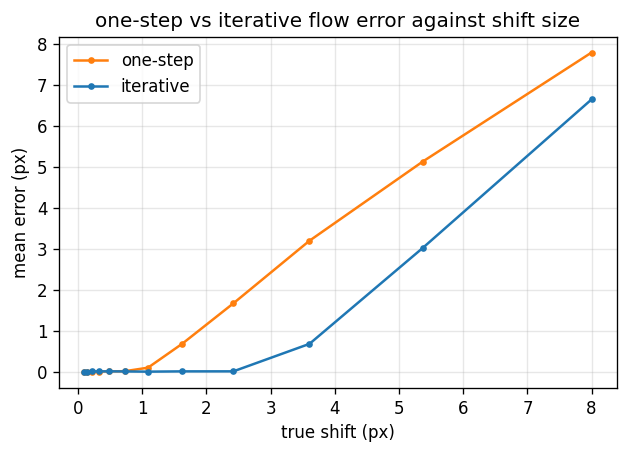

    shift  0.10 px: one-step 0.002 px, iterative 0.004 px
    shift  0.15 px: one-step 0.003 px, iterative 0.005 px
    shift  0.22 px: one-step 0.005 px, iterative 0.007 px
    shift  0.33 px: one-step 0.007 px, iterative 0.010 px
    shift  0.49 px: one-step 0.010 px, iterative 0.011 px
    shift  0.73 px: one-step 0.015 px, iterative 0.009 px
    shift  1.09 px: one-step 0.100 px, iterative 0.004 px
    shift  1.63 px: one-step 0.685 px, iterative 0.010 px
    shift  2.42 px: one-step 1.670 px, iterative 0.011 px
    shift  3.61 px: one-step 3.197 px, iterative 0.681 px
    shift  5.37 px: one-step 5.128 px, iterative 3.022 px
    shift  8.00 px: one-step 7.788 px, iterative 6.644 px


In [4]:
curves = error_sweep(select_features, spatial_gradients, one_step_flow, track_point)

**(a)** Up to what shift does the iterative tracker stay accurate?

*TODO*

## 3.2 Track many points (6 marks)

Track many points at once and mark a track as failed when its window leaves
either image or the least-squares system cannot be solved.

In [5]:
# YOUR CODE: Task 3.2

def track_points(image0, image1, points, window_radius=7, max_iterations=10, tolerance=1e-3,
                 initial=None):
    """Track many points with track_point (Task 3.2).

    Returns (tracked, valid): an (N, 2) array of new positions and an (N,) bool
    array, False for failed tracks.
    """
    points = np.asarray(points, dtype=np.float64).reshape(-1, 2)
    grad0 = spatial_gradients(image0)          # once, shared by every point
    n = len(points)
    tracked = np.zeros((n, 2))
    valid = np.zeros(n, dtype=bool)
    for k in range(n):
        start = None if initial is None else initial[k]
        tracked[k], valid[k] = track_point(image0, image1, points[k], window_radius,
                                           max_iterations, tolerance, grad0, start)
    return tracked, valid

In [6]:
check("3.2")

Task 3.2 checks
  PASS  track points accepts one initial guess per point
  PASS  track points returns positions and validity
2 of 2 passed


True

**(a)** Can a track that is marked valid still be wrong? Give an example from your results.

*TODO*

## 3.3 Use SIFT to handle large motion (7 marks)

The provided `track_with_sift` (in `provided/sift.py`) runs your `track_points`
from $(0, 0)$ and from a SIFT starting guess and keeps the better fit:

```python
tracked, valid = track_with_sift(track_points, image0, image1, points,
                                 sift_matches(image0, image1))
```

In [7]:
check("3.3")

Task 3.3 checks


  PASS  track with sift recovers motion too large for zero start
1 of 1 passed


True

**(a)** Why do iterative and SIFT-guided tracking give almost the same result on 375 to 376, but very different results on 300 to 301? Use the numbers of Task 3.4.

*TODO*

## 3.4 Compare the three trackers (8 marks)

Compare one-step, iterative and SIFT-guided tracking on the two pairs of
Task 2.3 and on a third pair near touchdown (409 to 410). The provided cells
print the numbers and overlay all three trackers in one figure per pair.

  small_motion (375 to 376)    one-step: mean 1.07 px, failed-track rate 0.02


  saved outputs/task3/small_motion_one_step.png
  small_motion (375 to 376)   iterative: mean 1.29 px, failed-track rate 0.02


  saved outputs/task3/small_motion_iterative.png
  small_motion (375 to 376) sift-guided: mean 1.29 px, failed-track rate 0.02


  saved outputs/task3/small_motion_sift_guided.png
  saved outputs/task3/small_motion_statistics.json


  saved outputs/task3/small_motion_compare.png


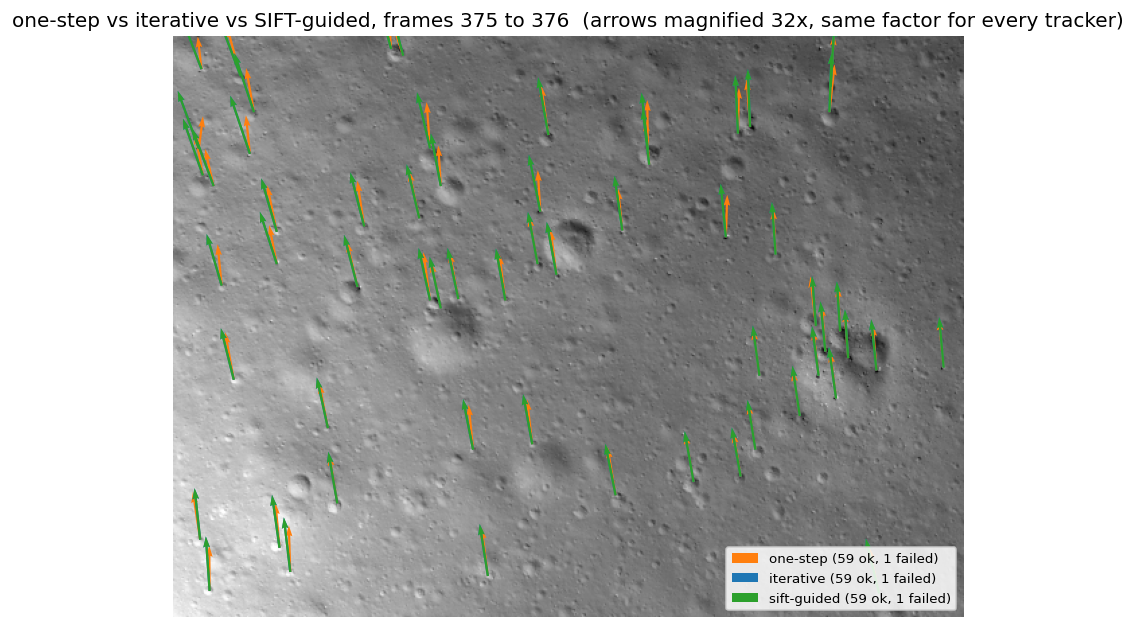

In [8]:
small = compare_pair("small_motion", select_features, track_points)

  large_motion (300 to 301)    one-step: mean 0.30 px, failed-track rate 0.08


  saved outputs/task3/large_motion_one_step.png
  large_motion (300 to 301)   iterative: mean 2.38 px, failed-track rate 0.08


  saved outputs/task3/large_motion_iterative.png


  large_motion (300 to 301) sift-guided: mean 10.03 px, failed-track rate 0.13


  saved outputs/task3/large_motion_sift_guided.png
  saved outputs/task3/large_motion_statistics.json


  saved outputs/task3/large_motion_compare.png


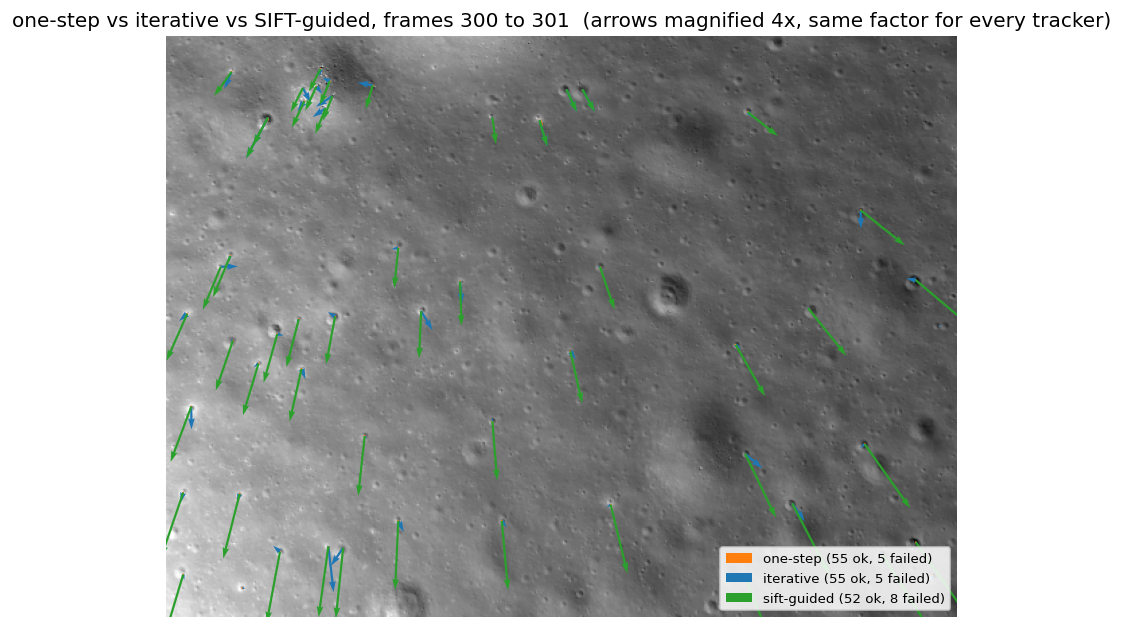

In [9]:
large = compare_pair("large_motion", select_features, track_points)

  touchdown (409 to 410)    one-step: mean 0.30 px, failed-track rate 0.10


  saved outputs/task3/touchdown_one_step.png
  touchdown (409 to 410)   iterative: mean 2.52 px, failed-track rate 0.13


  saved outputs/task3/touchdown_iterative.png


  touchdown (409 to 410) sift-guided: mean 32.74 px, failed-track rate 0.60


  saved outputs/task3/touchdown_sift_guided.png
  saved outputs/task3/touchdown_statistics.json


  saved outputs/task3/touchdown_compare.png


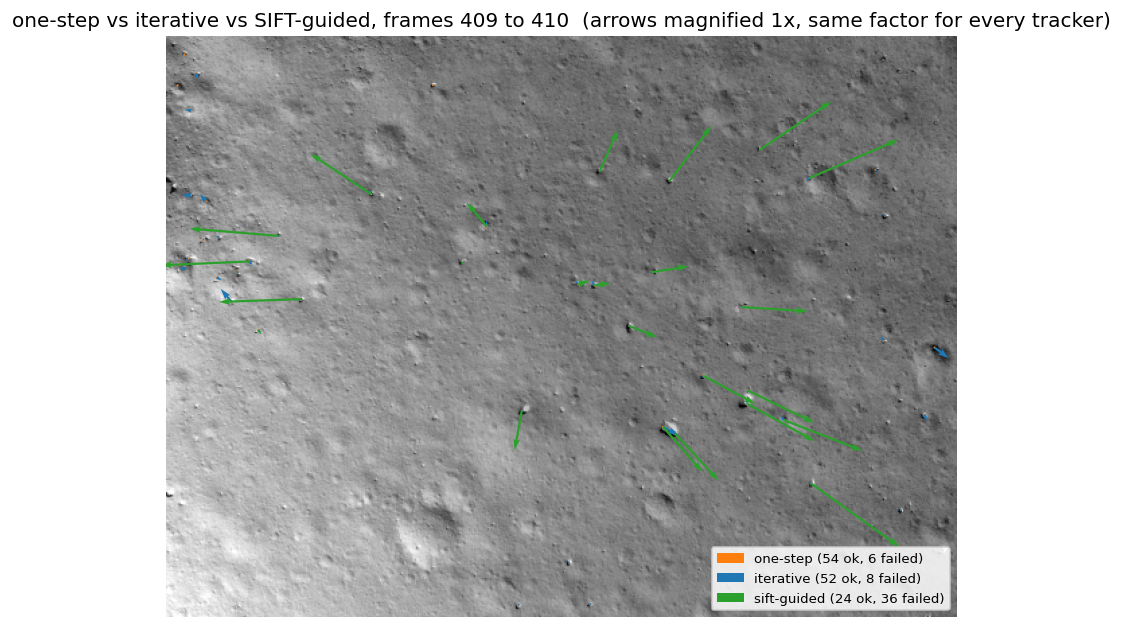

In [10]:
touchdown = compare_pair("touchdown", select_features, track_points)

**Table.** Fill in the mean displacement (px) and the failed-track rate (0 to 1) printed above.

| Pair | one-step | iterative | SIFT-guided |
|------|----------|-----------|-------------|
| 375 to 376 | *TODO* px, *TODO* | *TODO* px, *TODO* | *TODO* px, *TODO* |
| 300 to 301 | *TODO* px, *TODO* | *TODO* px, *TODO* | *TODO* px, *TODO* |
| 409 to 410 | *TODO* px, *TODO* | *TODO* px, *TODO* | *TODO* px, *TODO* |

**(a)** Which tracker is right on each pair?

*TODO*

**(b)** Why does SIFT-guided tracking lose many points at 409 to 410?

*TODO*